Correlation Matrix:
                            population       gdp      year  \
population                    1.000000  0.654951  0.027552   
gdp                           0.654951  1.000000  0.088583   
year                          0.027552  0.088583  1.000000   
primary_energy_consumption    0.642003  0.966042  0.042910   

                            primary_energy_consumption  
population                                    0.642003  
gdp                                           0.966042  
year                                          0.042910  
primary_energy_consumption                    1.000000  


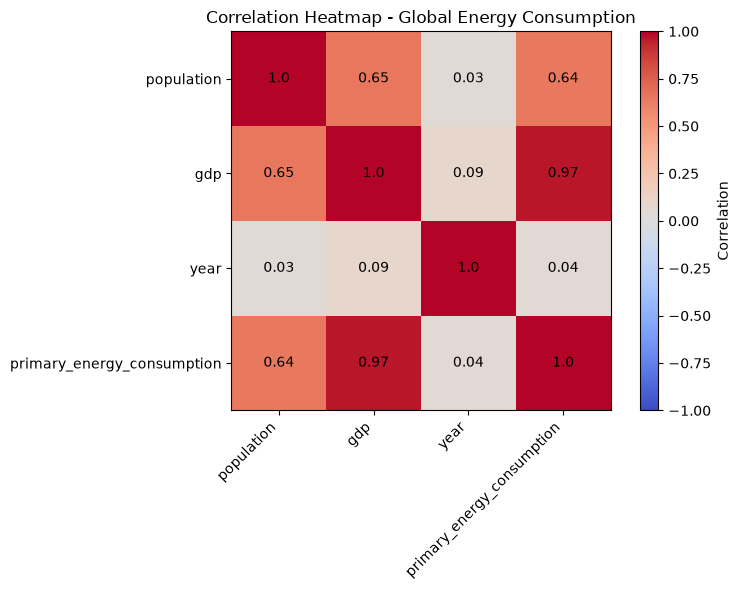

R2: 0.93
MAE: 248.9 TWh
RMSE: 683.1 TWh


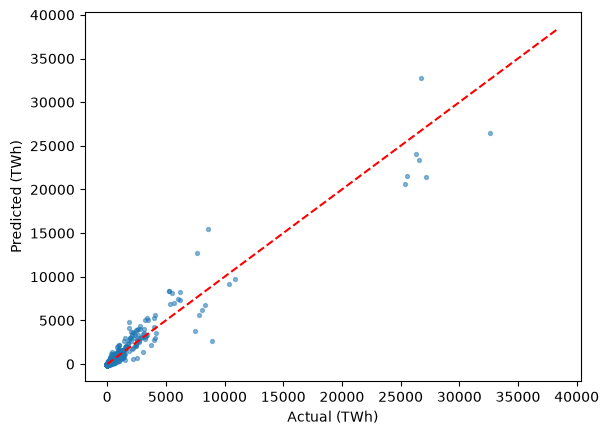

In [1]:
#1.Understanding The Datset
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error
import matplotlib.pyplot as plt

df = pd.read_csv("Dataset/World_Energy_Consumption.csv")
df = df[df["iso_code"].notna()] #Some of the countries in the dataset are not really countries, i.e. they are regions like africa that contain a lot of countries therefore only considering unique countries to avoid redundant data
df = df[df["year"] >= 1990] #Before 1990, i think the data was too little so we are only considering after that
#2. Data Preprocessing
df=df[["primary_energy_consumption","population","gdp","year"]].dropna()#required columns
X=df[["population","gdp","year"]]#features
y=df["primary_energy_consumption"]#target
# required columns are population,gdp,year,primary energy consumtion
correlation_data = df[["population","gdp","year","primary_energy_consumption"]].dropna()
correlation_matrix = correlation_data.corr()#calculating correlation matrix
print("Correlation Matrix:")
print(correlation_matrix)
plt.figure(figsize=(8, 6))#generate heat map
plt.imshow(correlation_matrix,cmap="coolwarm",vmin=-1,vmax=1)
plt.colorbar(label="Correlation")#adding colour bar
plt.xticks(range(len(correlation_matrix.columns)),correlation_matrix.columns,rotation=45,ha="right")
plt.yticks(range(len(correlation_matrix.columns)),correlation_matrix.columns)
# Display correlation values
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(j, i,round(correlation_matrix.iloc[i, j], 2),ha="center",va="center")
plt.title("Correlation Heatmap - Global Energy Consumption")
plt.tight_layout()
plt.savefig("output/correlation_heatmap.png")# Save heatmap
plt.show()# Display heatmap

#3. Model Training & Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
pd.DataFrame(pred).to_csv("output/Predicted_Values.csv")
pd.DataFrame(y_test).to_csv("output/test_Values.csv")
#4. Model Evaluation
print("R2:", round(r2_score(y_test, pred), 3))
print("MAE:", round(mean_absolute_error(y_test, pred), 1), "TWh")
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 1), "TWh")
plt.scatter(y_test, pred, s=8, alpha=0.5)
plt.plot([0, y.max()], [0, y.max()], "r--")
plt.xlabel("Actual (TWh)")
plt.ylabel("Predicted (TWh)")
plt.savefig("output/predicted_vs_actual.png")